In [59]:
import numpy as np
import pandas as pd
df = pd.read_csv("../dataprep/clean_segmentation_data_customer.csv")

In [60]:
df_encoded = pd.get_dummies(
    df,
    columns=["Country"],
    dtype=int
)

In [61]:
df_encoded.head()

,Unnamed: 0,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,MissingCustomer,Transaction_Total,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,False,15.30,...,0,0,0,0,0,0,0,0,1,0
1,1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
2,2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,False,22.00,...,0,0,0,0,0,0,0,0,1,0
3,3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0
4,4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,False,20.34,...,0,0,0,0,0,0,0,0,1,0


In [62]:
numeric_cols = df_encoded.select_dtypes(include="number").columns.tolist()
numeric_cols

['Unnamed: 0',
 'InvoiceNo',
 'Quantity',
 'UnitPrice',
 'CustomerID',
 'Transaction_Total',
 'Country_Australia',
 'Country_Austria',
 'Country_Bahrain',
 'Country_Belgium',
 'Country_Brazil',
 'Country_Canada',
 'Country_Channel Islands',
 'Country_Cyprus',
 'Country_Czech Republic',
 'Country_Denmark',
 'Country_EIRE',
 'Country_European Community',
 'Country_Finland',
 'Country_France',
 'Country_Germany',
 'Country_Greece',
 'Country_Iceland',
 'Country_Israel',
 'Country_Italy',
 'Country_Japan',
 'Country_Lebanon',
 'Country_Lithuania',
 'Country_Malta',
 'Country_Netherlands',
 'Country_Norway',
 'Country_Poland',
 'Country_Portugal',
 'Country_RSA',
 'Country_Saudi Arabia',
 'Country_Singapore',
 'Country_Spain',
 'Country_Sweden',
 'Country_Switzerland',
 'Country_USA',
 'Country_United Arab Emirates',
 'Country_United Kingdom',
 'Country_Unspecified']

In [63]:
numeric_cols.remove('CustomerID')
numeric_cols.remove('Unnamed: 0')
numeric_cols.remove('InvoiceNo')

In [64]:
customer_df = (
    df_encoded
    .groupby("CustomerID")[numeric_cols]
    .sum()
    .reset_index()
)

In [65]:
customer_df

,CustomerID,Quantity,UnitPrice,Transaction_Total,Country_Australia,Country_Austria,Country_Bahrain,Country_Belgium,Country_Brazil,Country_Canada,...,Country_RSA,Country_Saudi Arabia,Country_Singapore,Country_Spain,Country_Sweden,Country_Switzerland,Country_USA,Country_United Arab Emirates,Country_United Kingdom,Country_Unspecified
0,12346.0,74215,1.04,77183.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,1,0
1,12347.0,2458,481.21,4310.00,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
2,12348.0,2341,178.71,1797.24,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,12349.0,631,605.10,1757.55,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
4,12350.0,197,65.30,334.40,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,45,47.65,180.60,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,10,0
4334,18281.0,54,39.36,80.82,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,7,0
4335,18282.0,103,62.39,178.05,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,12,0
4336,18283.0,1357,1174.33,2045.53,0,0,0,0,0,0,...,0,0,0,0,0,0,0,0,721,0


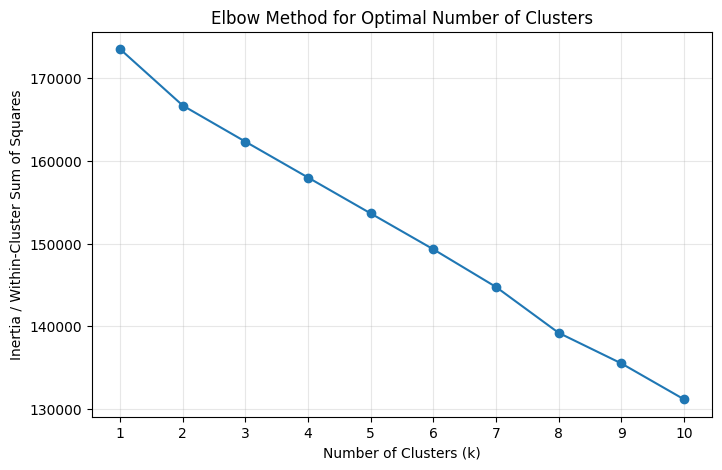

In [66]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [67]:
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

X = customer_df.drop(columns="CustomerID")
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X)

kmeans = KMeans(
    n_clusters=2,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

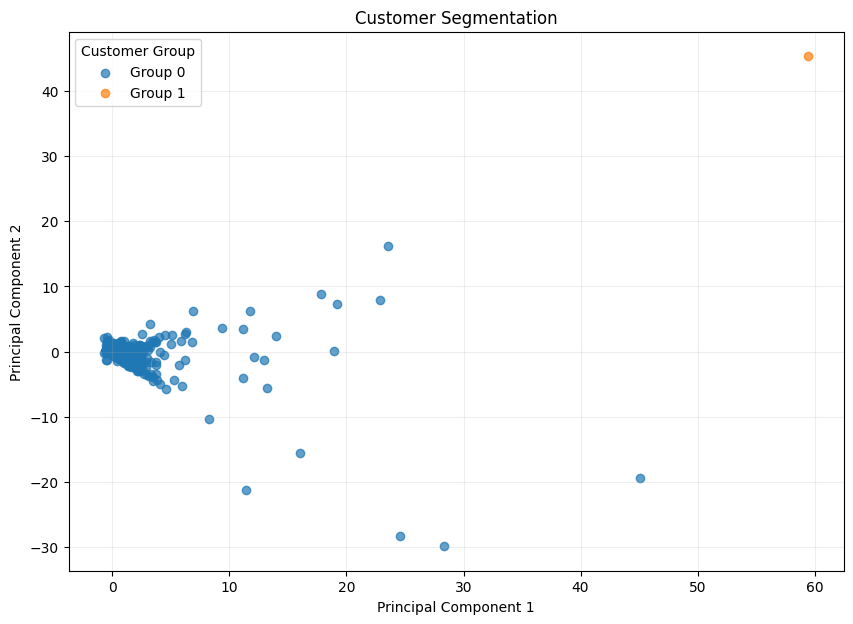

In [68]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

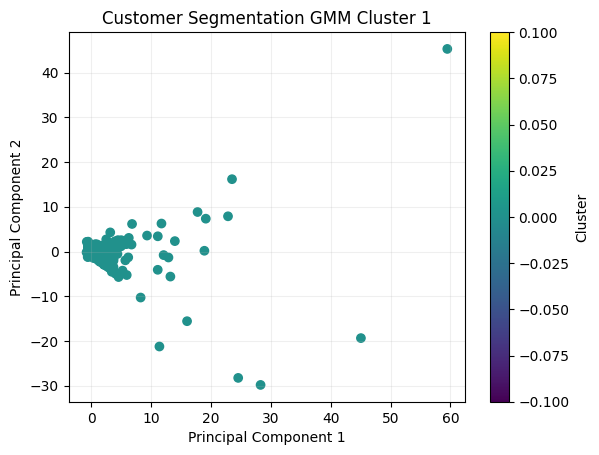

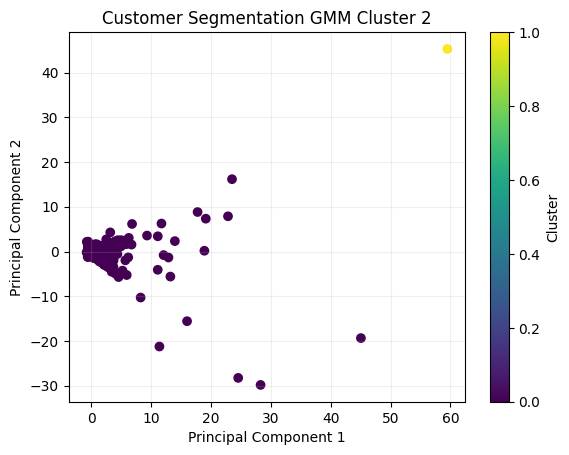

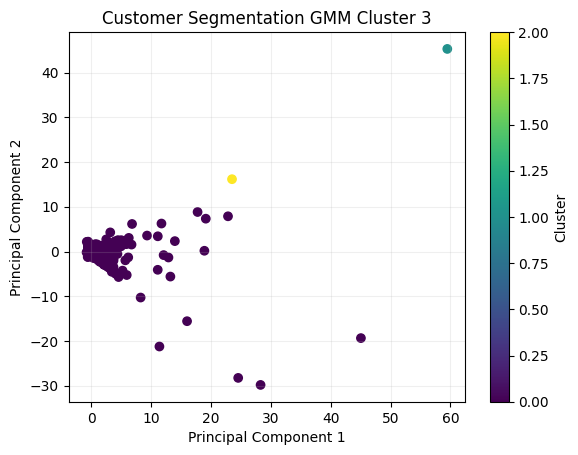

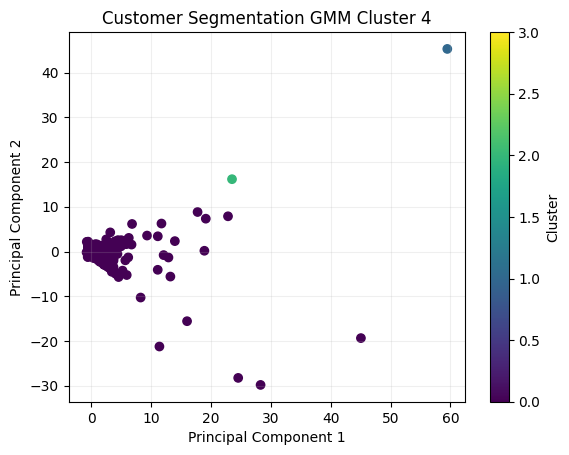

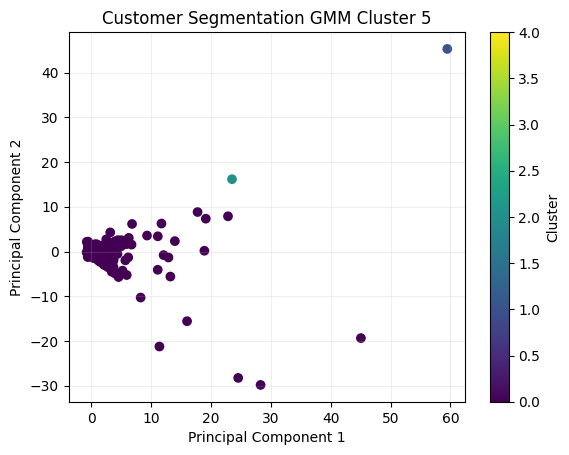

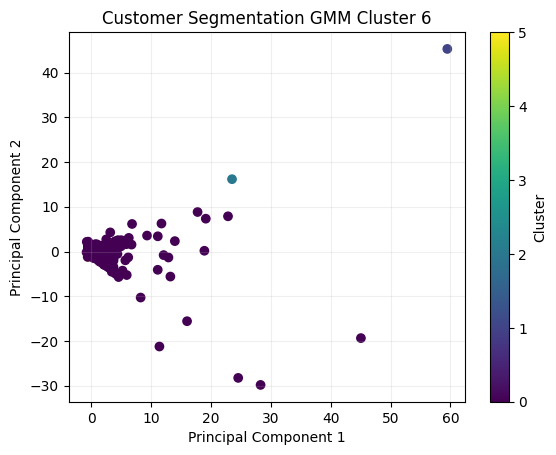

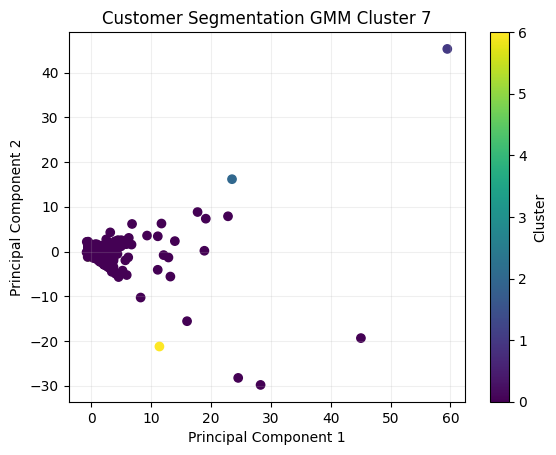

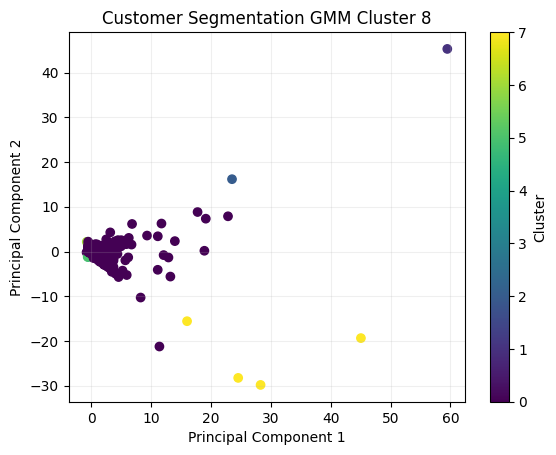

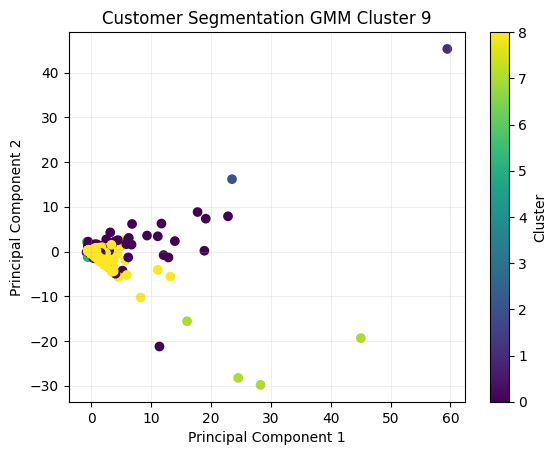

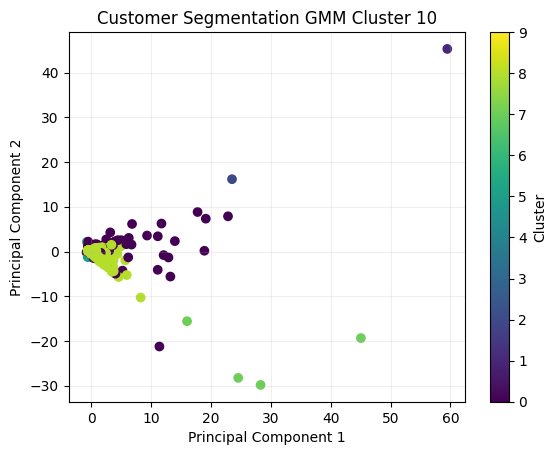

In [69]:
from sklearn.mixture import GaussianMixture

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
    )
    
    labels = gmm.fit_predict(X_scaled)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [70]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = (
    df.groupby("CustomerID")
      .agg(
          monetary=("Transaction_Total", "sum"),
          frequency=("InvoiceNo", "nunique"),
          total_quantity=("Quantity", "sum"),
          unique_products=("StockCode", "nunique"),
          last_purchase=("InvoiceDate", "max")
      )
      .reset_index()
)

customer_df.head()

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00


In [71]:
customer_df['avg_purchase_val'] = customer_df['monetary'] / customer_df['frequency']
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000
...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625


In [72]:
customer_df['recency'] = (reference_date - customer_df['last_purchase']).dt.days
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,last_purchase,avg_purchase_val,recency
0,12346.0,77183.60,1,74215,1,2011-01-18 10:01:00,77183.600000,326
1,12347.0,4310.00,7,2458,103,2011-12-07 15:52:00,615.714286,2
2,12348.0,1797.24,4,2341,22,2011-09-25 13:13:00,449.310000,75
3,12349.0,1757.55,1,631,73,2011-11-21 09:51:00,1757.550000,19
4,12350.0,334.40,1,197,17,2011-02-02 16:01:00,334.400000,310
...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,2011-03-07 09:52:00,180.600000,278
4334,18281.0,80.82,1,54,7,2011-06-12 10:53:00,80.820000,181
4335,18282.0,178.05,2,103,12,2011-12-02 11:43:00,89.025000,8
4336,18283.0,2045.53,16,1357,263,2011-12-06 12:02:00,127.845625,4


In [73]:
customer_df = customer_df.drop(columns=["last_purchase"])

In [74]:
customer_df.describe()

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency
count,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000,4338.000000
mean,15300.408022,2048.688081,4.272015,1187.644537,61.501153,417.645735,92.536422
std,1721.808492,8985.230220,7.697998,5043.619654,85.366768,1796.511343,100.014169
min,12346.000000,3.750000,1.000000,1.000000,1.000000,3.450000,1.000000
25%,13813.250000,306.482500,1.000000,159.000000,16.000000,177.867083,18.000000
50%,15299.500000,668.570000,2.000000,378.000000,35.000000,291.940000,51.000000
75%,16778.750000,1660.597500,5.000000,989.750000,77.000000,428.280625,142.000000
max,18287.000000,280206.020000,209.000000,196915.000000,1787.000000,84236.250000,374.000000


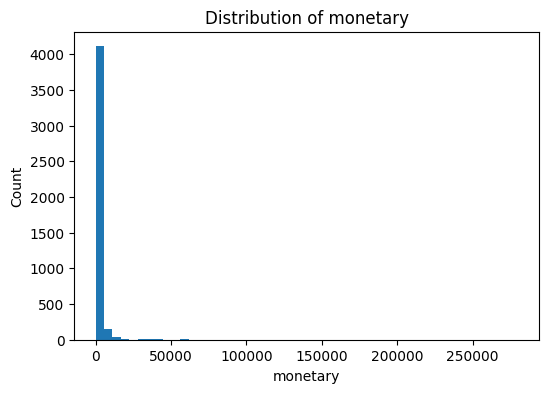

In [75]:
import matplotlib.pyplot as plt

plt.figure(figsize=(6, 4))
plt.hist(customer_df['monetary'], bins=50)
plt.title(f"Distribution of monetary")
plt.xlabel('monetary')
plt.ylabel("Count")
plt.show()

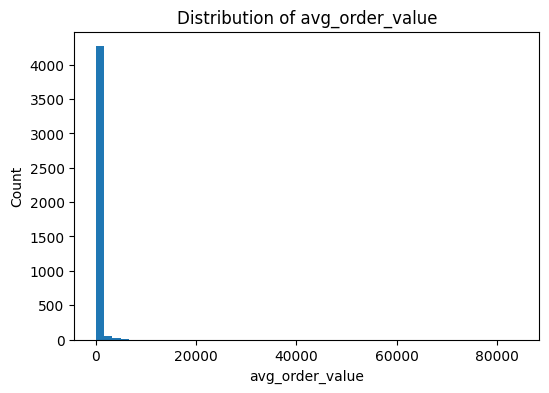

In [76]:
plt.figure(figsize=(6, 4))
plt.hist(customer_df['avg_purchase_val'], bins=50)
plt.title(f"Distribution of avg_order_value")
plt.xlabel('avg_order_value')
plt.ylabel("Count")
plt.show()

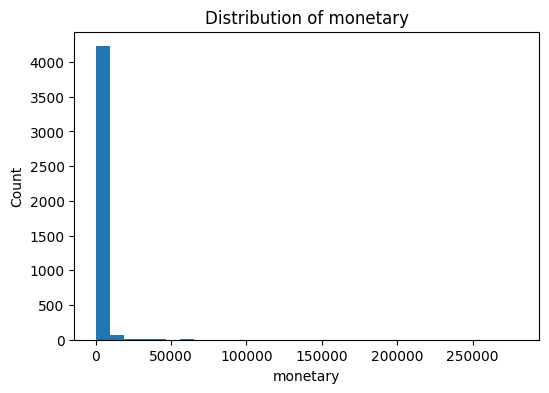

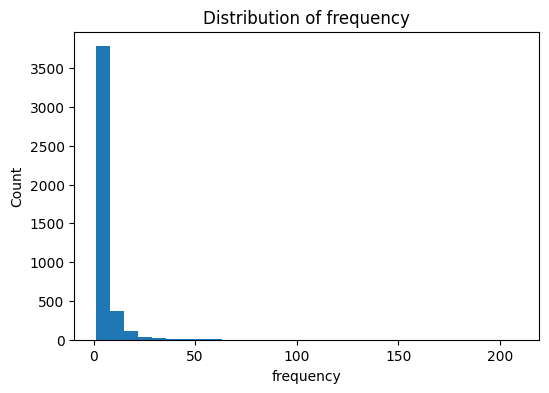

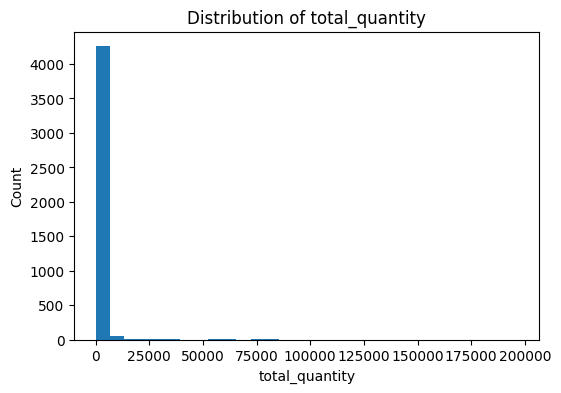

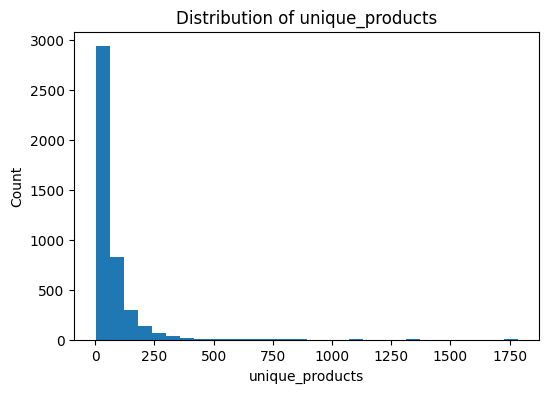

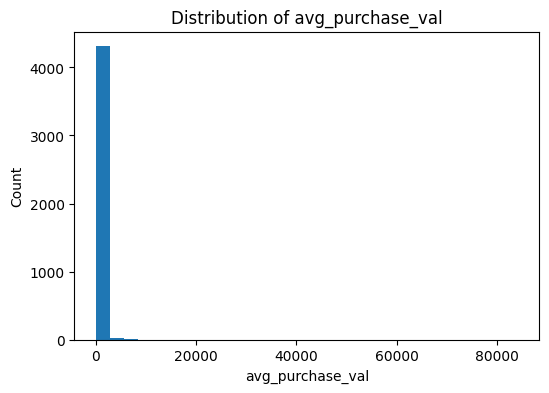

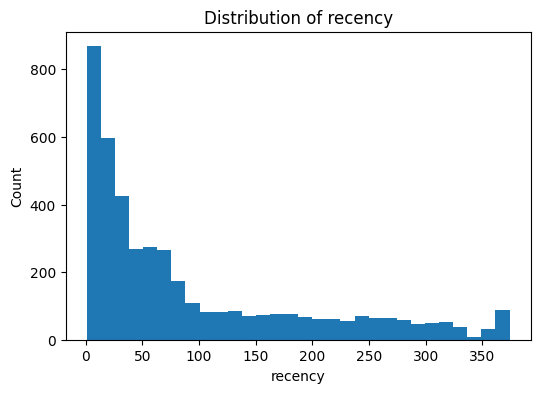

In [77]:
import matplotlib.pyplot as plt

features = [
    "monetary",
    "frequency",
    "total_quantity",
    "unique_products",
    "avg_purchase_val",
    'recency'
]

for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[col], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [78]:
import numpy as np
features = [
    "monetary",
    "frequency",
    "total_quantity",
    "unique_products",
    "avg_purchase_val"]


for col in features:
    customer_df[f"log_{col}"] = np.log1p(customer_df[col])

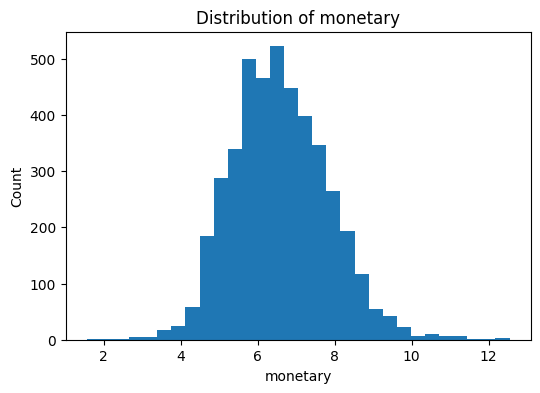

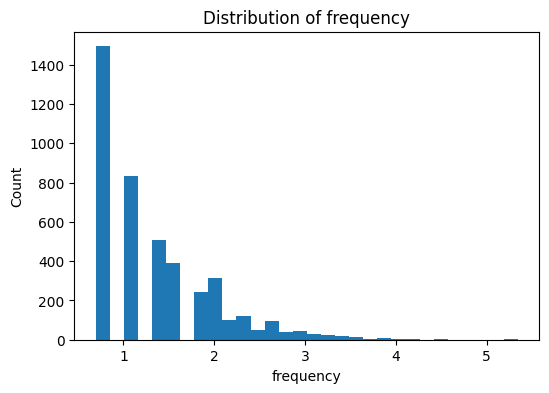

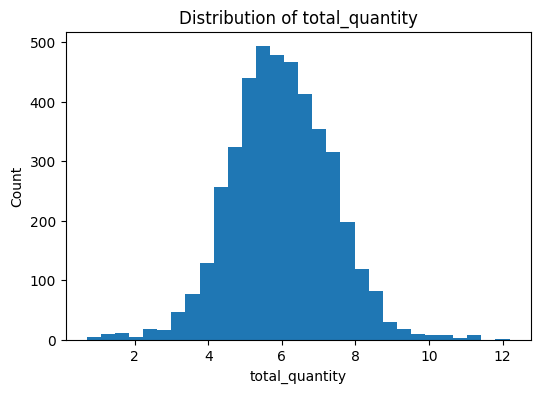

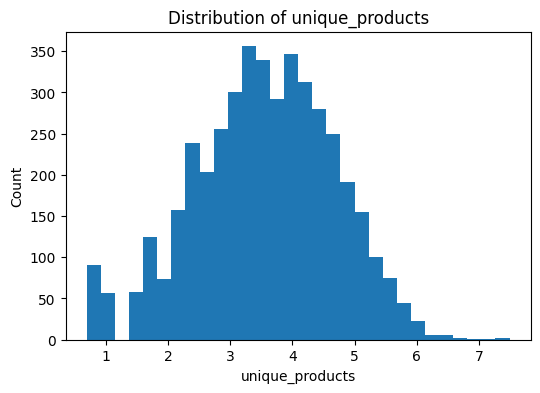

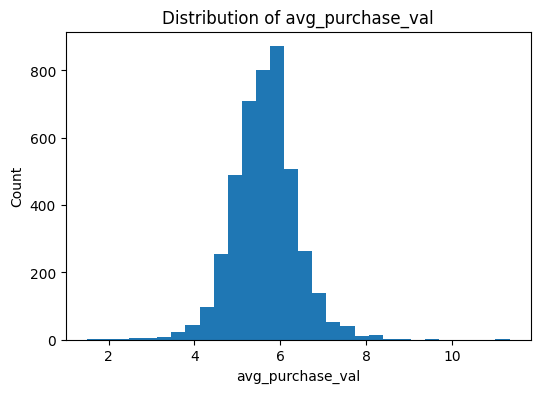

In [79]:
for col in features:
    plt.figure(figsize=(6, 4))
    plt.hist(customer_df[f"log_{col}"], bins=30)
    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Count")
    plt.show()

In [80]:
customer_df

,CustomerID,monetary,frequency,total_quantity,unique_products,avg_purchase_val,recency,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val
0,12346.0,77183.60,1,74215,1,77183.600000,326,11.253955,0.693147,11.214735,0.693147,11.253955
1,12347.0,4310.00,7,2458,103,615.714286,2,8.368925,2.079442,7.807510,4.644391,6.424406
2,12348.0,1797.24,4,2341,22,449.310000,75,7.494564,1.609438,7.758761,3.135494,6.109936
3,12349.0,1757.55,1,631,73,1757.550000,19,7.472245,0.693147,6.448889,4.304065,7.472245
4,12350.0,334.40,1,197,17,334.400000,310,5.815324,0.693147,5.288267,2.890372,5.815324
...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,180.60,1,45,10,180.600000,278,5.201806,0.693147,3.828641,2.397895,5.201806
4334,18281.0,80.82,1,54,7,80.820000,181,4.404522,0.693147,4.007333,2.079442,4.404522
4335,18282.0,178.05,2,103,12,89.025000,8,5.187665,1.098612,4.644391,2.564949,4.500087
4336,18283.0,2045.53,16,1357,263,127.845625,4,7.623901,2.833213,7.213768,5.575949,4.858615


In [81]:
from sklearn.preprocessing import StandardScaler

model_features = [
    "log_monetary",
    "log_frequency",
    "log_total_quantity",
    "log_unique_products",
    "log_avg_purchase_val",
    "recency"
]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 6)

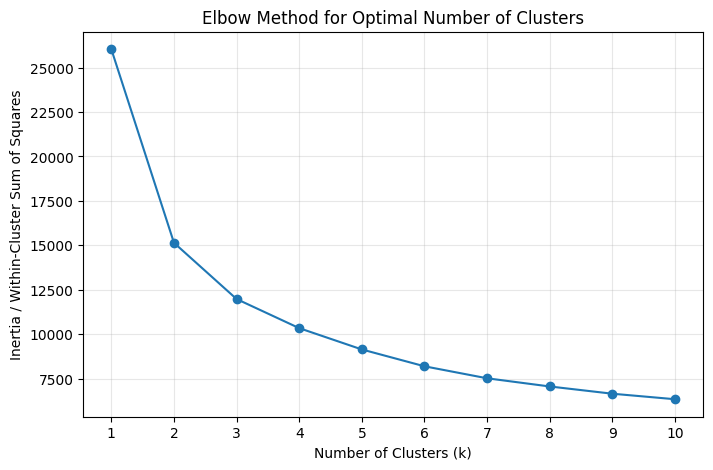

In [82]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [83]:
results

[{'k': 2, 'silhouette_score': 0.35087972449004934},
 {'k': 3, 'silhouette_score': 0.27233856936839324},
 {'k': 4, 'silhouette_score': 0.27399238588005786},
 {'k': 5, 'silhouette_score': 0.24079500780616786},
 {'k': 6, 'silhouette_score': 0.24415073069456075},
 {'k': 7, 'silhouette_score': 0.23076296777819227},
 {'k': 8, 'silhouette_score': 0.22364332616920457},
 {'k': 9, 'silhouette_score': 0.21659909598091084},
 {'k': 10, 'silhouette_score': 0.21664041376811313}]

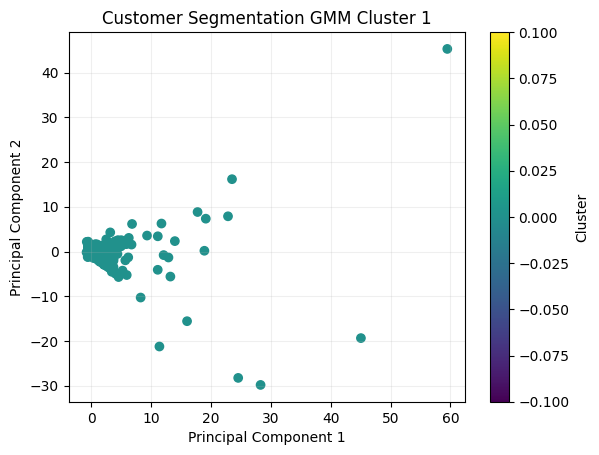

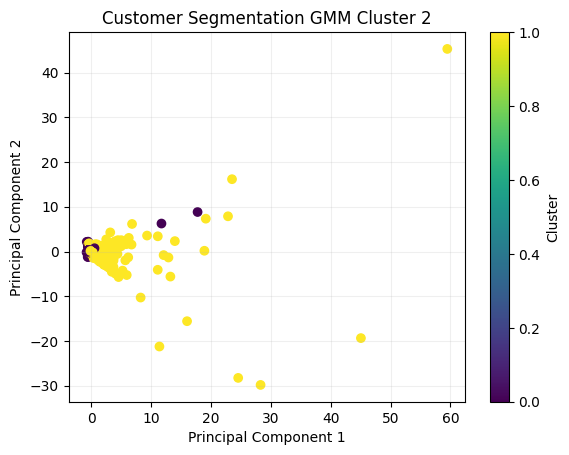

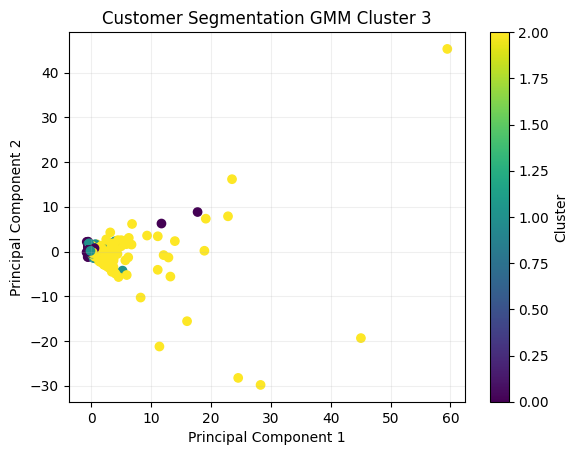

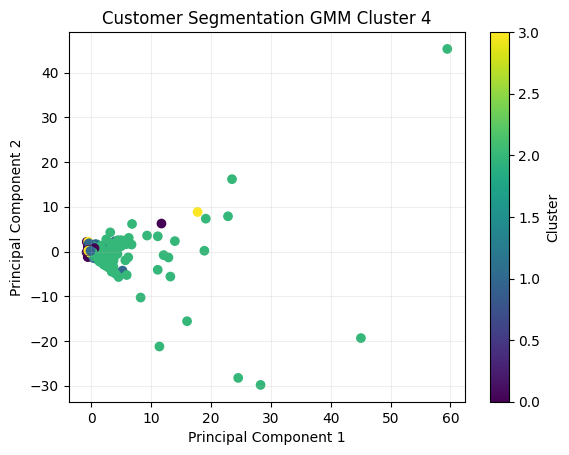

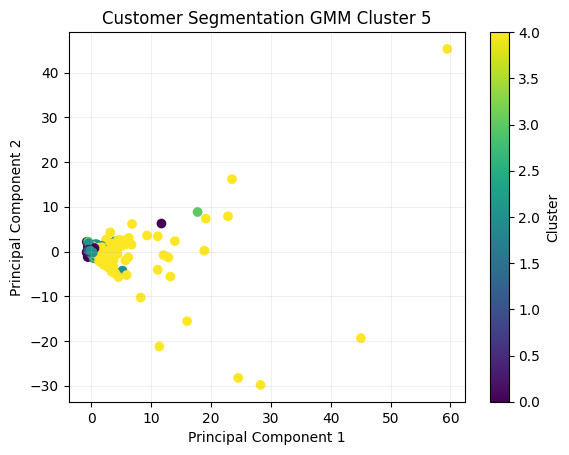

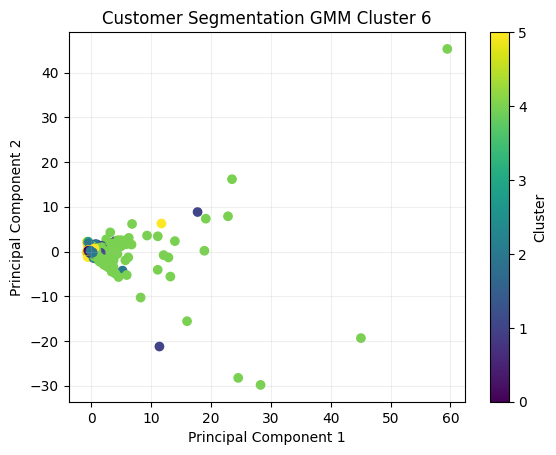

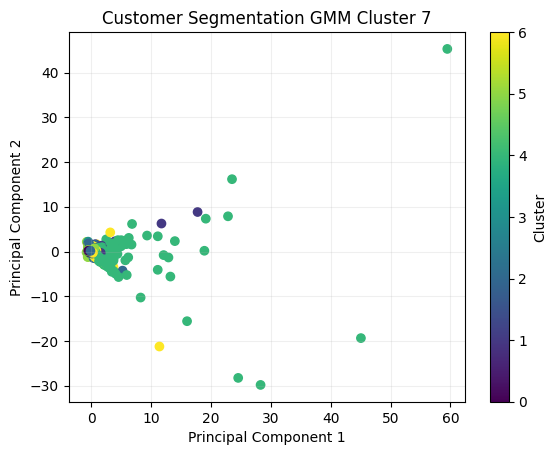

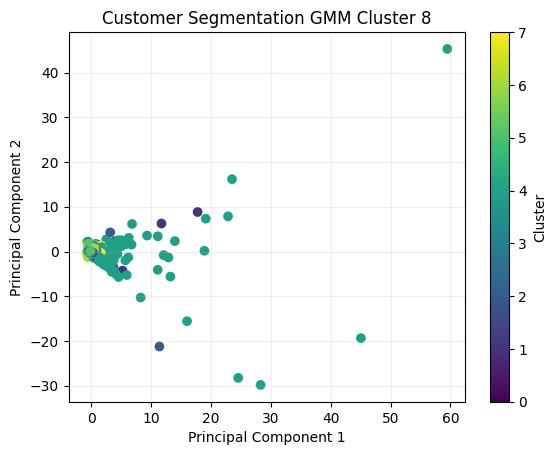

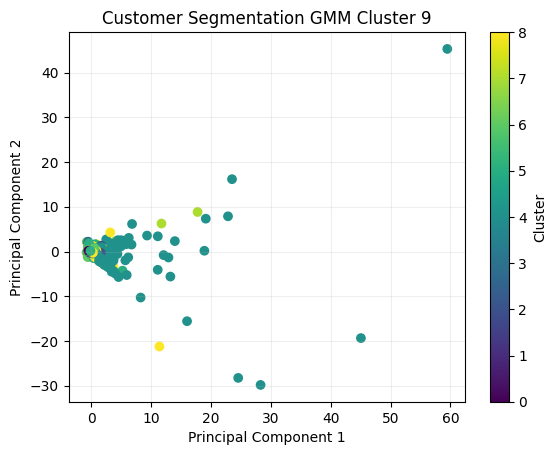

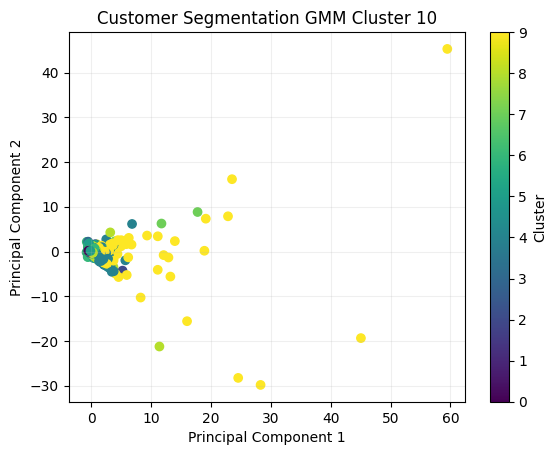

In [84]:
from sklearn.mixture import GaussianMixture

for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
    )
    
    labels = gmm.fit_predict(X_scaled)
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [85]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

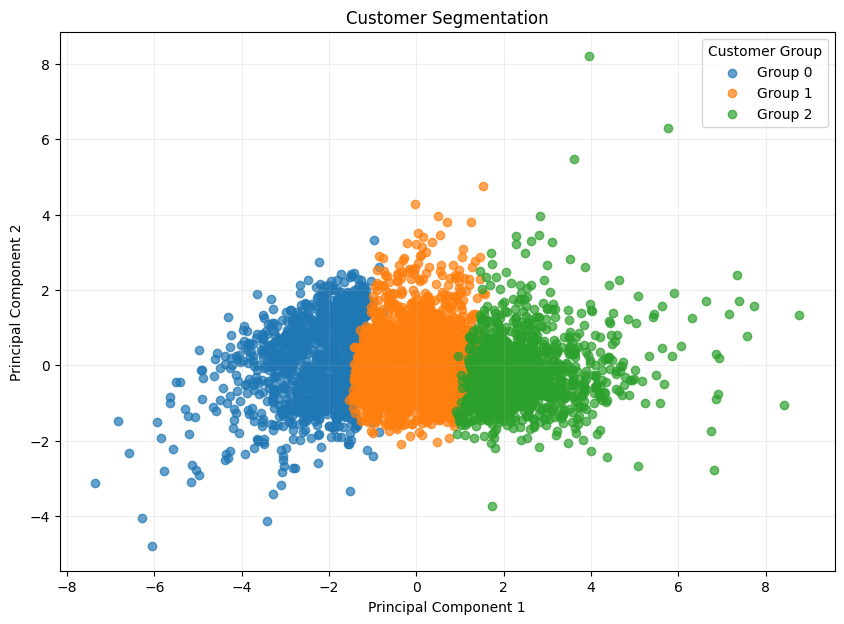

In [86]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

In [87]:
customer_df[model_features].corr()

,log_monetary,log_frequency,log_total_quantity,log_unique_products,log_avg_purchase_val,recency
log_monetary,1.000000,0.808119,0.921667,0.692399,0.708863,-0.434169
log_frequency,0.808119,1.000000,0.752504,0.622730,0.164300,-0.472760
log_total_quantity,0.921667,0.752504,1.000000,0.701705,0.642217,-0.452703
log_unique_products,0.692399,0.622730,0.701705,1.000000,0.403010,-0.418400
log_avg_purchase_val,0.708863,0.164300,0.642217,0.403010,1.000000,-0.138638
recency,-0.434169,-0.472760,-0.452703,-0.418400,-0.138638,1.000000


In [88]:
from sklearn.preprocessing import StandardScaler

model_features = [
    "log_frequency",
    "log_unique_products",
    "log_avg_purchase_val",
    "recency"
]
scaler = StandardScaler()
X = customer_df[model_features]
X_scaled = scaler.fit_transform(X)
# X_scaled = customer_df[model_features]

X_scaled.shape

(4338, 4)

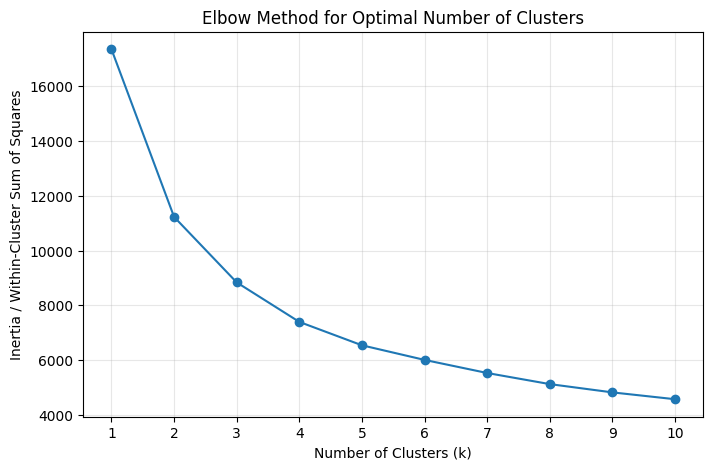

In [89]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

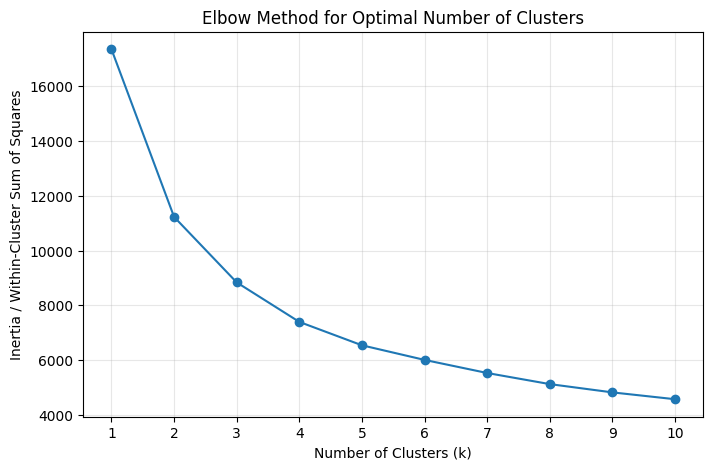

In [90]:
inertia = []
k_values = range(1, 11)
results = []
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score


for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    labels = kmeans.fit_predict(X_scaled)
    if k >= 2:
        score = silhouette_score(X_scaled, labels)

        results.append({
            "k": k,
            "silhouette_score": score
        })
    inertia.append(kmeans.inertia_)


plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [91]:
results

[{'k': 2, 'silhouette_score': 0.31015871895355135},
 {'k': 3, 'silhouette_score': 0.2850039810724538},
 {'k': 4, 'silhouette_score': 0.26314985212400066},
 {'k': 5, 'silhouette_score': 0.24428434650781977},
 {'k': 6, 'silhouette_score': 0.2358414087524427},
 {'k': 7, 'silhouette_score': 0.23321248819291643},
 {'k': 8, 'silhouette_score': 0.21596791292438206},
 {'k': 9, 'silhouette_score': 0.21186066804534134},
 {'k': 10, 'silhouette_score': 0.21797955505066394}]

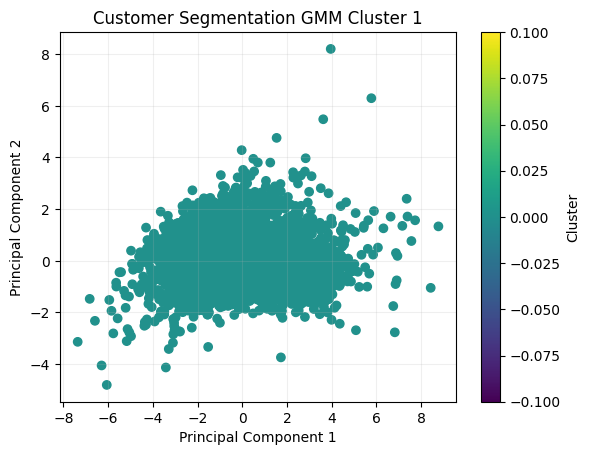

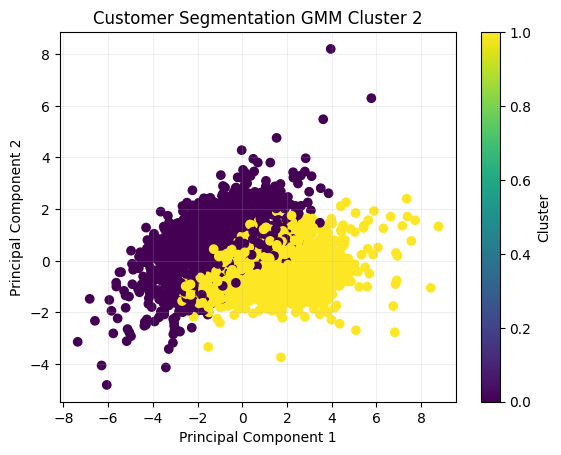

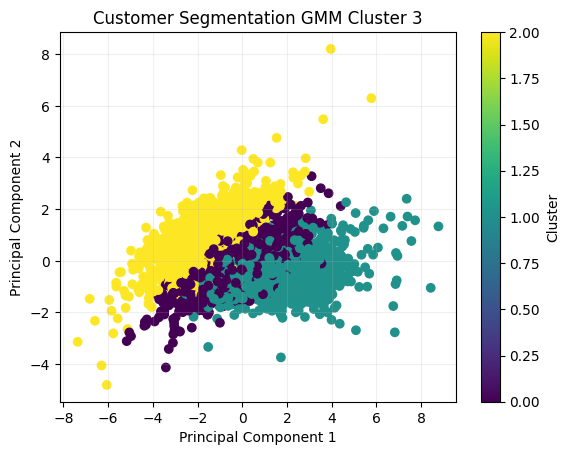

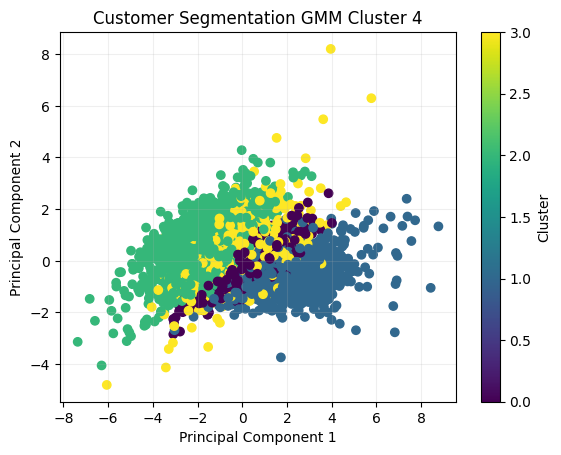

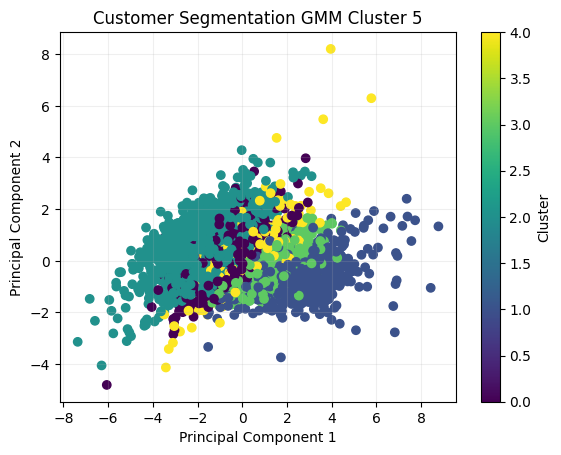

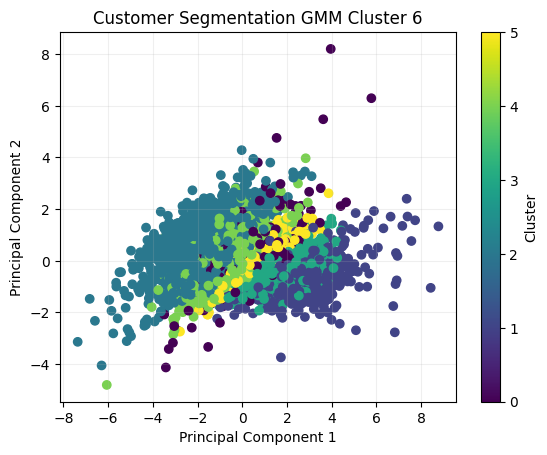

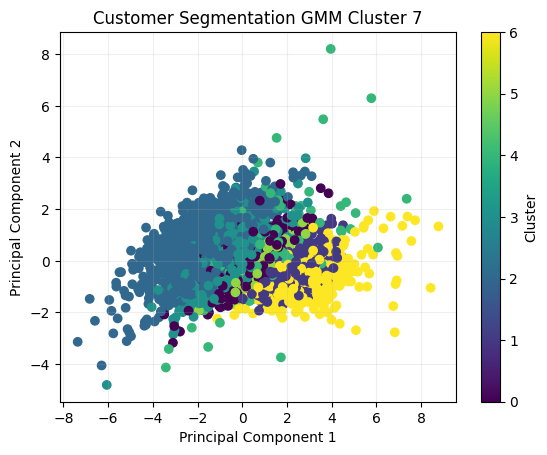

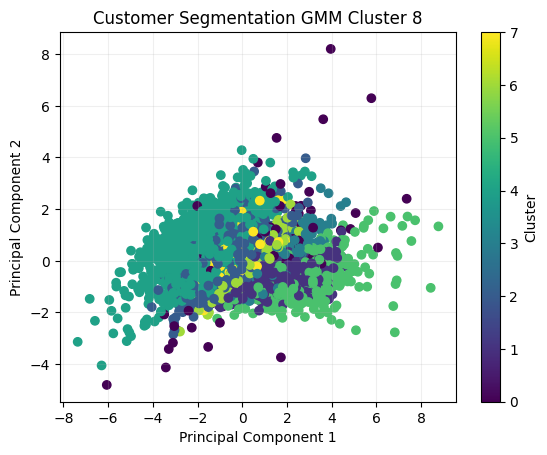

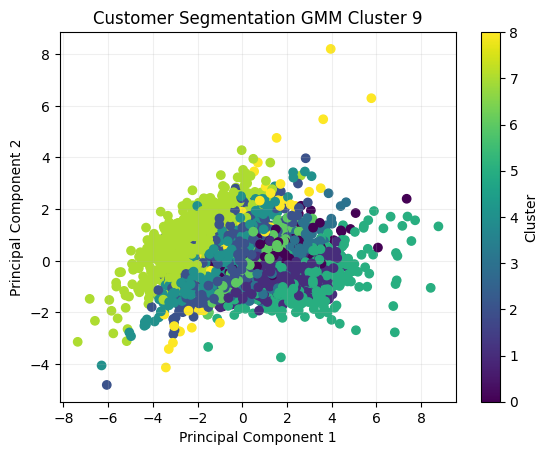

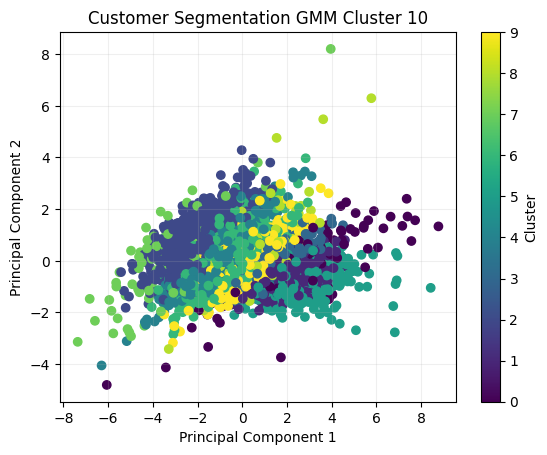

In [92]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [93]:
result

[{'K-val': 1,
  'AIC': 45069.42592739552,
  'BIC': 45158.67828907493,
  'Log-likelihood': -5.191496764337888},
 {'K-val': 2,
  'AIC': 40075.1191467551,
  'BIC': 40259.99903880532,
  'Log-likelihood': -4.612392709400081},
 {'K-val': 3,
  'AIC': 38951.34035734798,
  'BIC': 39231.847779769,
  'Log-likelihood': -4.4794076022761615},
 {'K-val': 4,
  'AIC': 22572.996741123345,
  'BIC': 22949.131693915166,
  'Log-likelihood': -2.588173898239205},
 {'K-val': 5,
  'AIC': 14110.310072067936,
  'BIC': 14582.072555230561,
  'Log-likelihood': -1.6093026823499235},
 {'K-val': 6,
  'AIC': 13681.540036352675,
  'BIC': 14248.930049886101,
  'Log-likelihood': -1.5564246238304145},
 {'K-val': 7,
  'AIC': 8982.723170073967,
  'BIC': 9645.740713978195,
  'Log-likelihood': -1.0113788808291801},
 {'K-val': 8,
  'AIC': 13265.366455752468,
  'BIC': 14024.0115300275,
  'Log-likelihood': -1.5015406242222762},
 {'K-val': 9,
  'AIC': 12564.397432016447,
  'BIC': 13418.67003666228,
  'Log-likelihood': -1.4172887773

In [94]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

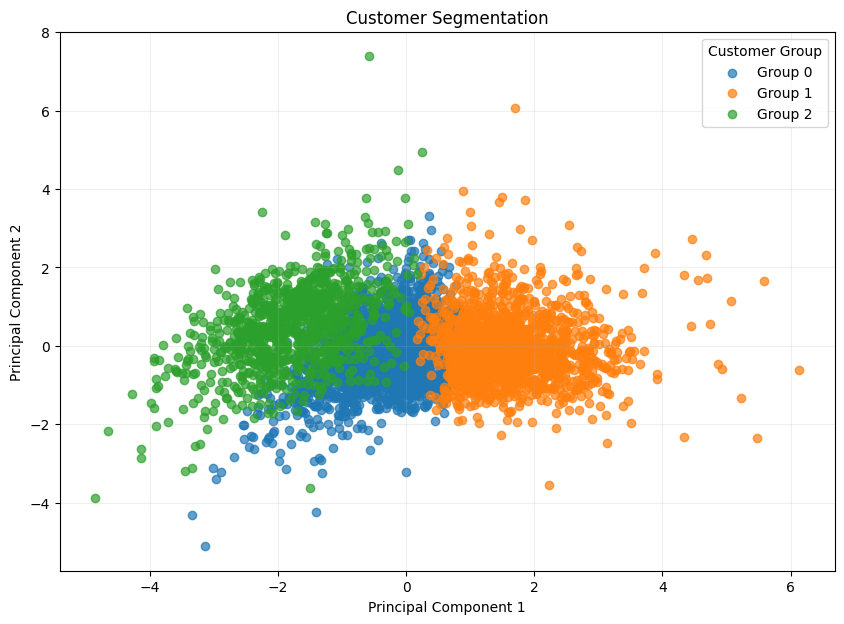

In [95]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

## RFM Baseline

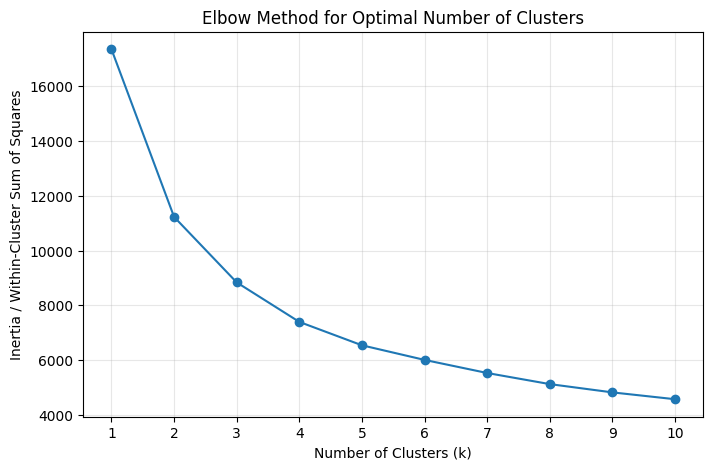

In [96]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [97]:
kmeans = KMeans(
    n_clusters=3,
    random_state=42,
    n_init="auto"
)

customer_df["cluster"] = kmeans.fit_predict(X_scaled)

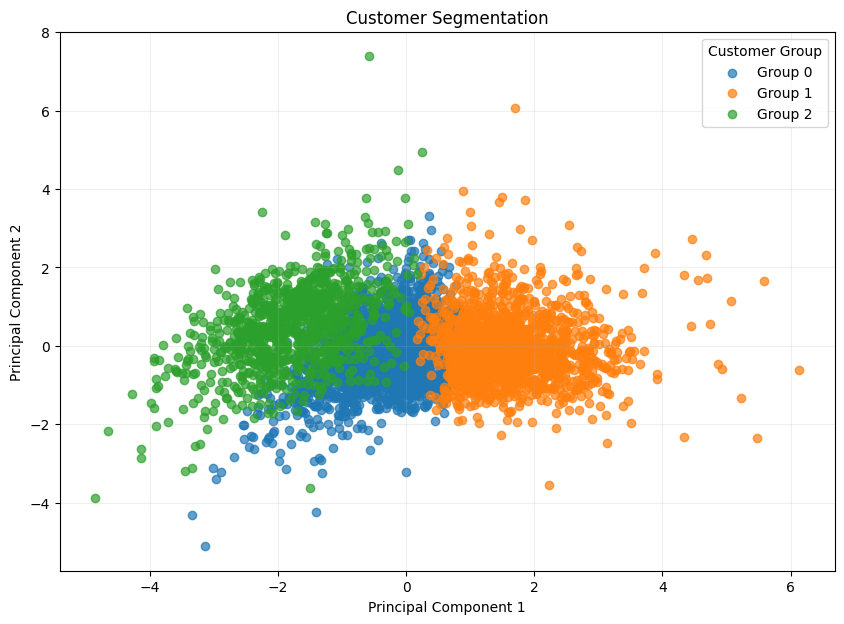

In [98]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

customer_df["PC1"] = X_pca[:, 0]
customer_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(customer_df["cluster"].unique()):
    subset = customer_df[
        customer_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

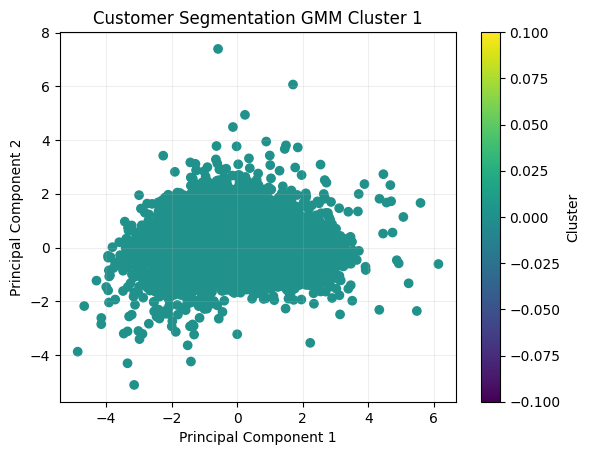

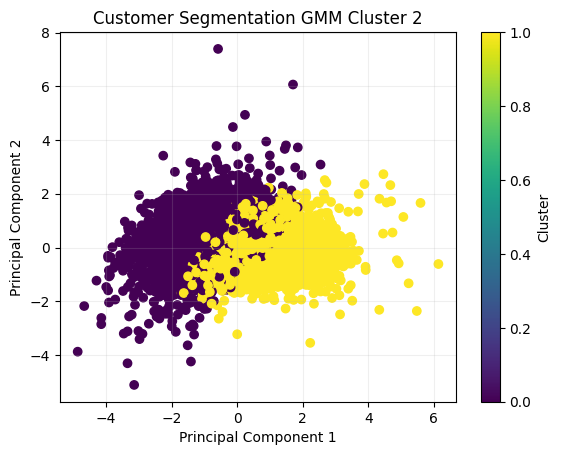

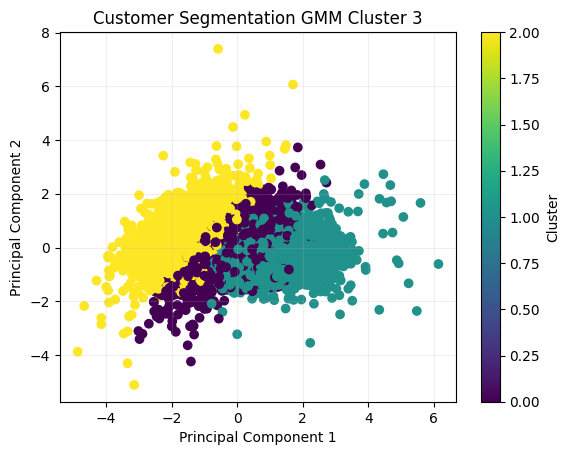

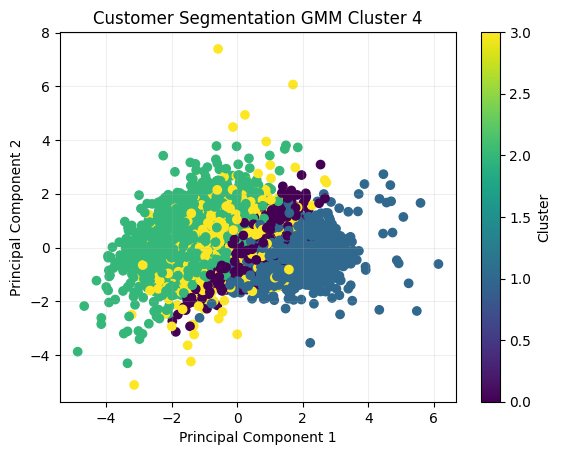

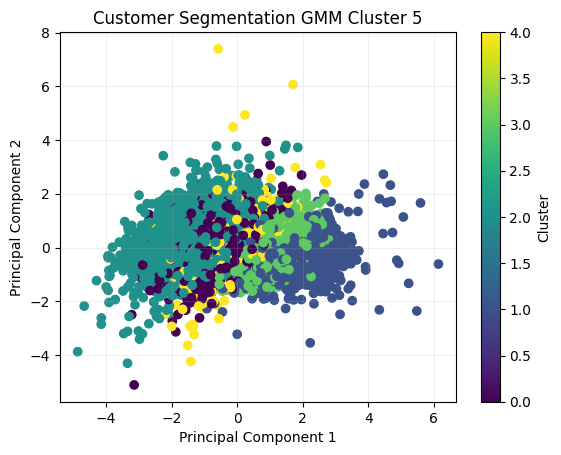

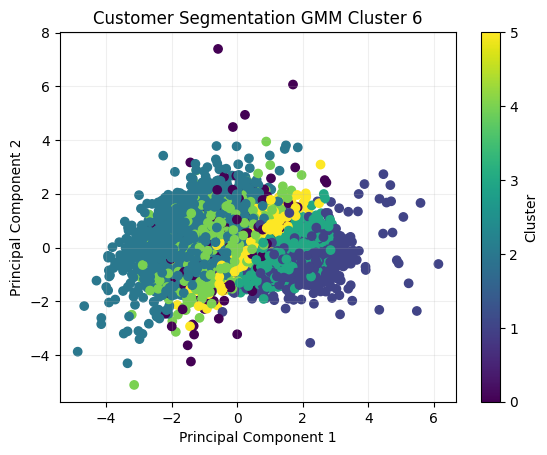

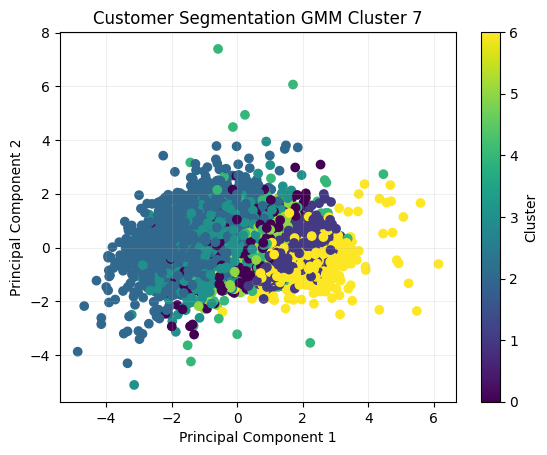

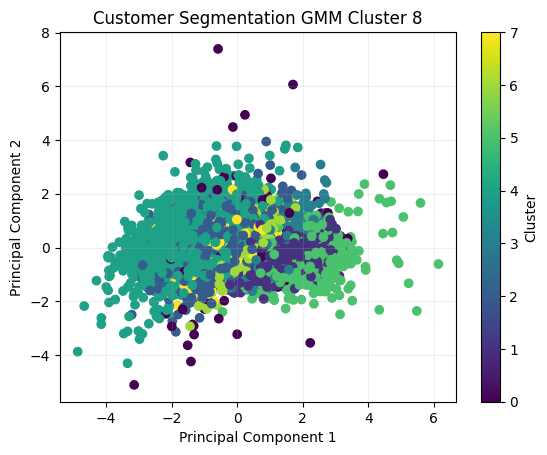

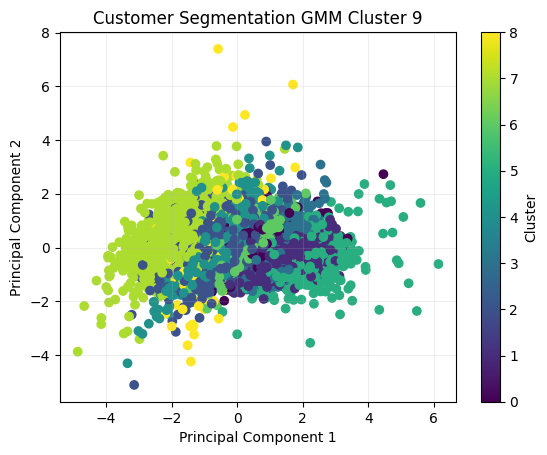

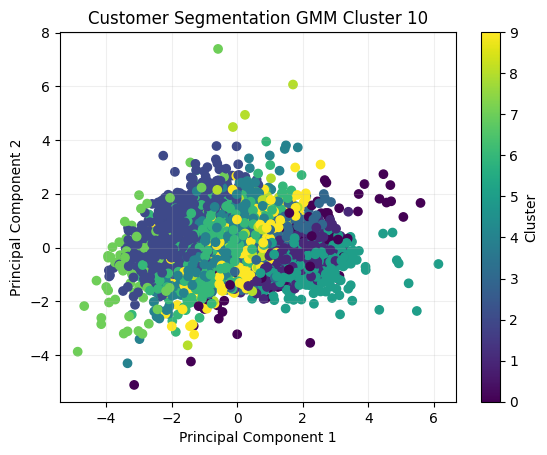

In [99]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [100]:
result

[{'K-val': 1,
  'AIC': 45069.42592739552,
  'BIC': 45158.67828907493,
  'Log-likelihood': -5.191496764337888},
 {'K-val': 2,
  'AIC': 40075.1191467551,
  'BIC': 40259.99903880532,
  'Log-likelihood': -4.612392709400081},
 {'K-val': 3,
  'AIC': 38951.34035734798,
  'BIC': 39231.847779769,
  'Log-likelihood': -4.4794076022761615},
 {'K-val': 4,
  'AIC': 22572.996741123345,
  'BIC': 22949.131693915166,
  'Log-likelihood': -2.588173898239205},
 {'K-val': 5,
  'AIC': 14110.310072067936,
  'BIC': 14582.072555230561,
  'Log-likelihood': -1.6093026823499235},
 {'K-val': 6,
  'AIC': 13681.540036352675,
  'BIC': 14248.930049886101,
  'Log-likelihood': -1.5564246238304145},
 {'K-val': 7,
  'AIC': 8982.723170073967,
  'BIC': 9645.740713978195,
  'Log-likelihood': -1.0113788808291801},
 {'K-val': 8,
  'AIC': 13265.366455752468,
  'BIC': 14024.0115300275,
  'Log-likelihood': -1.5015406242222762},
 {'K-val': 9,
  'AIC': 12564.397432016447,
  'BIC': 13418.67003666228,
  'Log-likelihood': -1.4172887773

In [101]:
# reference: https://www.geeksforgeeks.org/data-analysis/rfm-analysis-analysis-using-python/

rfm_df = customer_df[
    ["CustomerID", "recency", "frequency", "monetary"]
].copy()


rfm_df["R_rank"] = rfm_df["recency"].rank(ascending=False)
rfm_df["F_rank"] = rfm_df["frequency"].rank(ascending=True)
rfm_df["M_rank"] = rfm_df["monetary"].rank(ascending=True)

rfm_df["R_rank_norm"] = (
    rfm_df["R_rank"] / rfm_df["R_rank"].max()
) * 100

rfm_df["F_rank_norm"] = (
    rfm_df["F_rank"] / rfm_df["F_rank"].max()
) * 100

rfm_df["M_rank_norm"] = (
    rfm_df["M_rank"] / rfm_df["M_rank"].max()
) * 100

rfm_df["RFM_score"] = (
    0.15 * rfm_df["R_rank_norm"]
    + 0.28 * rfm_df["F_rank_norm"]
    + 0.57 * rfm_df["M_rank_norm"]
)

rfm_df["RFM_score"] *= 0.05

rfm_df["RFM_score"] = rfm_df["RFM_score"].round(2)

In [102]:
rfm_feature = [
    "R_rank_norm",
    "F_rank_norm",
    "M_rank_norm"
]

In [103]:
scaler = StandardScaler()
X = rfm_df[rfm_feature]
X_scaled = scaler.fit_transform(X)

X_scaled.shape

(4338, 3)

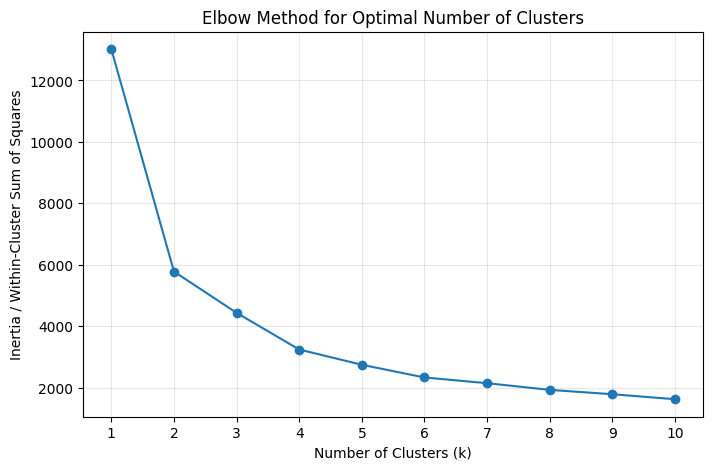

In [104]:
inertia = []
k_values = range(1, 11)
for k in k_values:
    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init="auto"
    )
    
    kmeans.fit(X_scaled)
    inertia.append(kmeans.inertia_)

plt.figure(figsize=(8, 5))

plt.plot(
    k_values,
    inertia,
    marker="o"
)

plt.xlabel("Number of Clusters (k)")
plt.ylabel("Inertia / Within-Cluster Sum of Squares")
plt.title("Elbow Method for Optimal Number of Clusters")
plt.xticks(k_values)
plt.grid(alpha=0.3)

plt.show()

In [105]:
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init="auto"
)

rfm_df["cluster"] = kmeans.fit_predict(X_scaled)

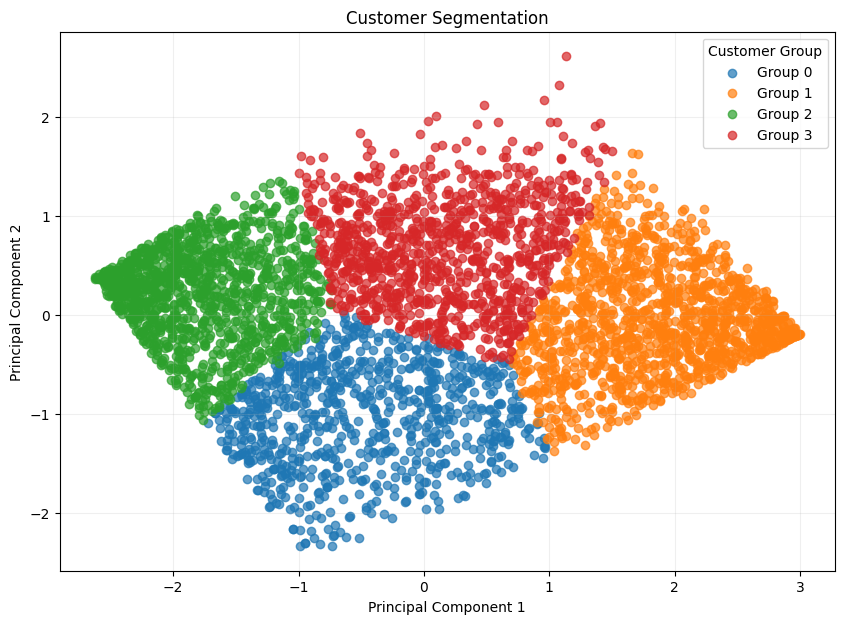

In [106]:
from sklearn.decomposition import PCA
import matplotlib.pyplot as plt

pca = PCA(n_components=2)

X_pca = pca.fit_transform(X_scaled)

rfm_df["PC1"] = X_pca[:, 0]
rfm_df["PC2"] = X_pca[:, 1]



plt.figure(figsize=(10, 7))

for cluster in sorted(rfm_df["cluster"].unique()):
    subset = rfm_df[
        rfm_df["cluster"] == cluster
    ]

    plt.scatter(
        subset["PC1"],
        subset["PC2"],
        label=f"Group {cluster}",
        alpha=0.7
    )

plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("Customer Segmentation")
plt.legend(title="Customer Group")
plt.grid(alpha=0.2)

plt.show()

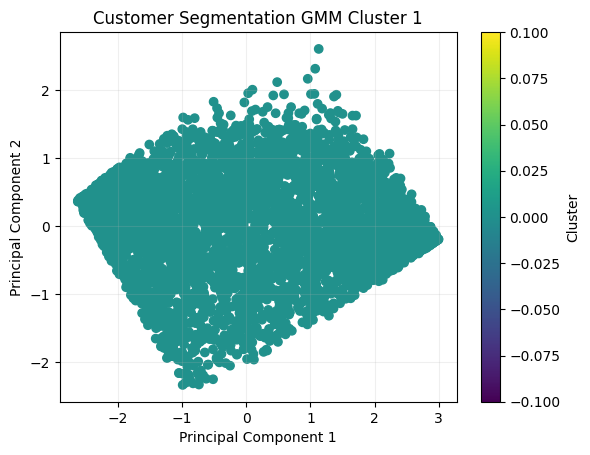

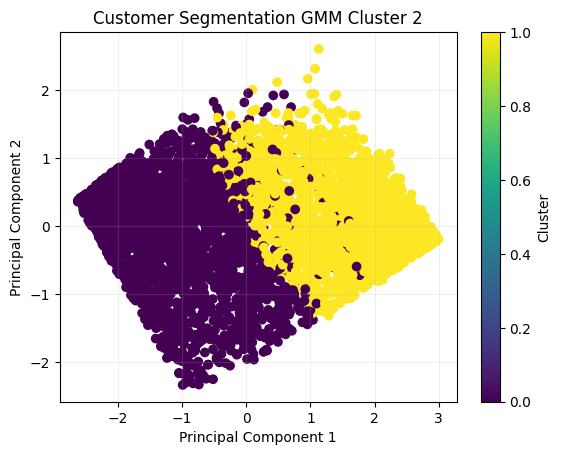

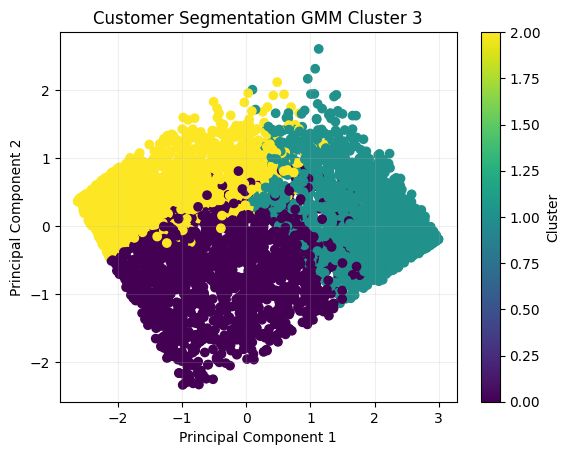

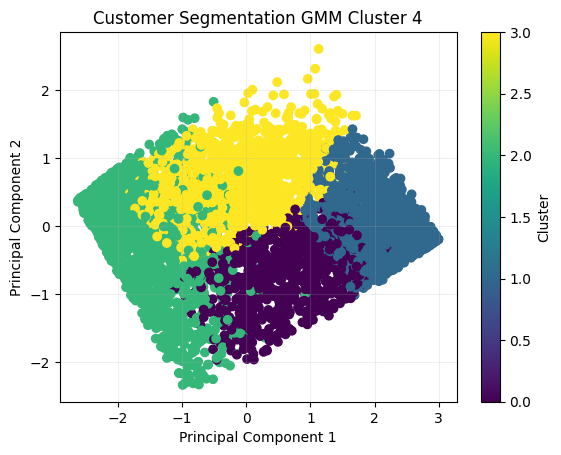

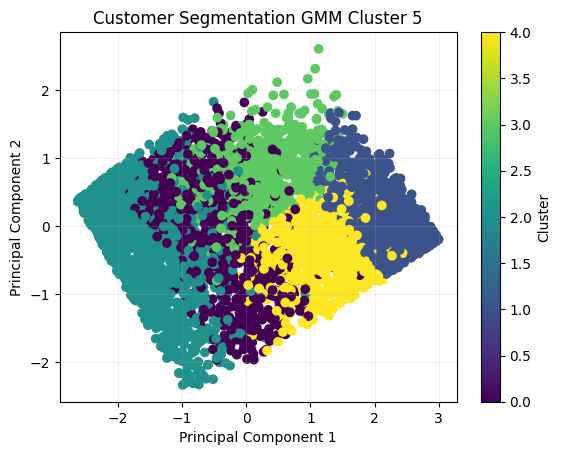

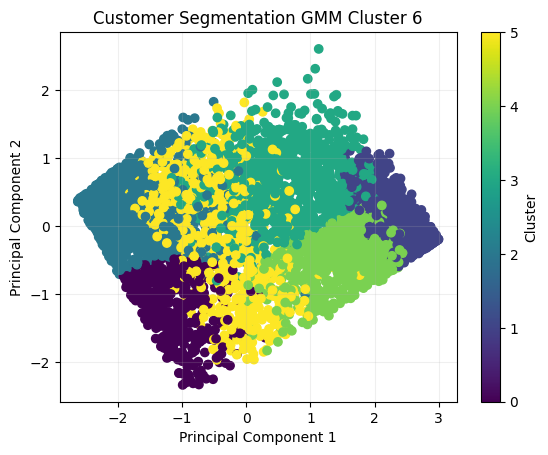

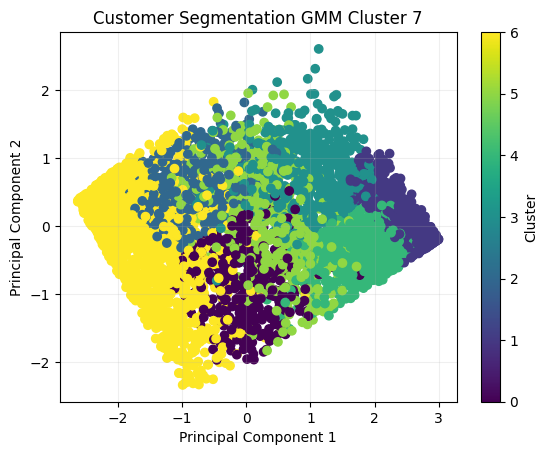

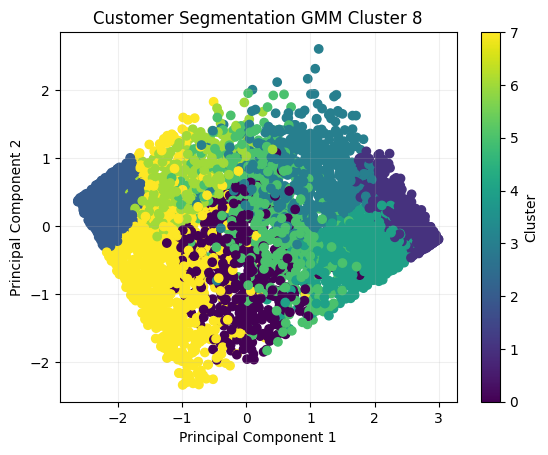

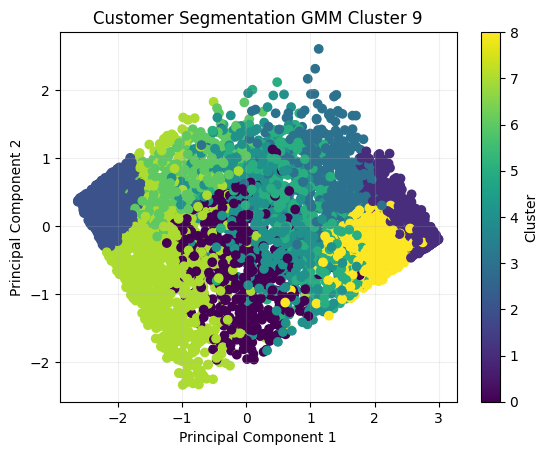

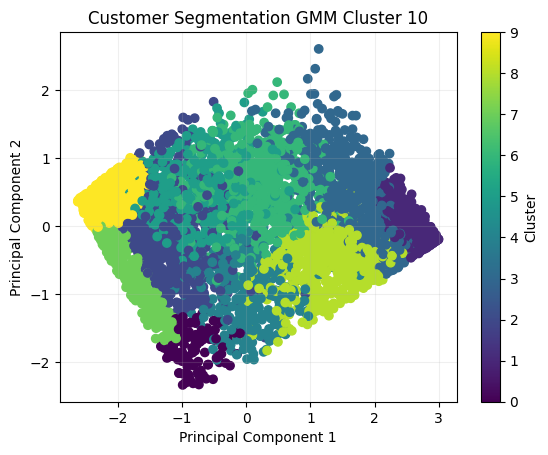

In [107]:
from sklearn.mixture import GaussianMixture
result = []
for k in k_values:
    gmm = GaussianMixture(
        n_components=k,
        random_state=42,
        covariance_type='full'
    )
    
    labels = gmm.fit_predict(X_scaled)
    
    result.append({"K-val": k, "AIC": gmm.aic(X_scaled), "BIC": gmm.bic(X_scaled), "Log-likelihood": gmm.score(X_scaled)})
    plt.scatter(X_pca[:, 0], X_pca[:, 1], c=labels)
    plt.title(f"Customer Segmentation GMM Cluster {k}")
    plt.xlabel("Principal Component 1")
    plt.ylabel("Principal Component 2")
    plt.colorbar(label="Cluster")
    plt.grid(alpha=0.2)

    plt.show()

In [108]:
result

[{'K-val': 1,
  'AIC': 30714.449233870295,
  'BIC': 30771.825752092776,
  'Log-likelihood': -3.5380877401879087},
 {'K-val': 2,
  'AIC': 29276.897464413763,
  'BIC': 29398.025669550112,
  'Log-likelihood': -3.3700896109282805},
 {'K-val': 3,
  'AIC': 28531.41587900251,
  'BIC': 28716.29577105273,
  'Log-likelihood': -3.2818598292995054},
 {'K-val': 4,
  'AIC': 10251.763249309024,
  'BIC': 10500.39482827311,
  'Log-likelihood': -1.1726329240789561},
 {'K-val': 5,
  'AIC': 815.2438639409052,
  'BIC': 1127.6271298188594,
  'Log-likelihood': -0.08266987827811263},
 {'K-val': 6,
  'AIC': 446.45540595438456,
  'BIC': 822.5903587462069,
  'Log-likelihood': -0.03785793060792814},
 {'K-val': 7,
  'AIC': -4704.143475139028,
  'BIC': -4264.256835433337,
  'Log-likelihood': 0.5581078233216953},
 {'K-val': 8,
  'AIC': -5309.032150724506,
  'BIC': -4805.393824104947,
  'Log-likelihood': 0.6301327974555678},
 {'K-val': 9,
  'AIC': -9106.666940291841,
  'BIC': -8539.276926758415,
  'Log-likelihood': 1

In [109]:
rfm_df.sort_values(by='RFM_score', ascending=False)

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
1879,14911.0,1,201,143711.17,4292.0,4337.0,4334.0,100.000000,99.976948,99.907792,5.00,1,2.996402,-0.190390
4201,18102.0,1,60,259657.30,4292.0,4328.0,4337.0,100.000000,99.769479,99.976948,5.00,1,2.993274,-0.191274
2176,15311.0,1,91,60632.75,4292.0,4333.0,4325.0,100.000000,99.884740,99.700323,4.99,1,2.990078,-0.194507
326,12748.0,1,209,33053.19,4292.0,4338.0,4310.0,100.000000,100.000000,99.354541,4.98,1,2.985449,-0.198821
1689,14646.0,2,73,280206.02,4202.5,4331.0,4338.0,97.914725,99.838635,100.000000,4.98,1,2.958806,-0.129385
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1815,14821.0,367,1,48.80,54.5,747.0,37.0,1.269804,17.219917,0.852928,0.27,2,-2.600610,0.359455
1650,14589.0,372,1,39.75,33.0,747.0,29.0,0.768872,17.219917,0.668511,0.27,2,-2.613190,0.371195
1640,14576.0,372,1,35.40,33.0,747.0,20.0,0.768872,17.219917,0.461042,0.26,2,-2.617487,0.367951
402,12855.0,373,1,38.10,17.0,747.0,25.0,0.396086,17.219917,0.576302,0.26,2,-2.621618,0.380636


In [119]:
category_range = rfm_df.groupby('cluster')['RFM_score'].agg(lambda x: x.max() - x.min())
category_range

cluster
0    2.89
1    2.23
2    2.03
3    2.68
Name: RFM_score, dtype: float64

In [120]:
rfm_df['cluster'].value_counts()

cluster
1    1283
2    1207
3    1018
0     830
Name: count, dtype: int64

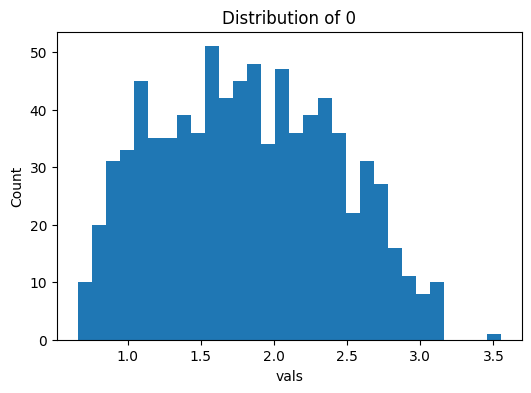

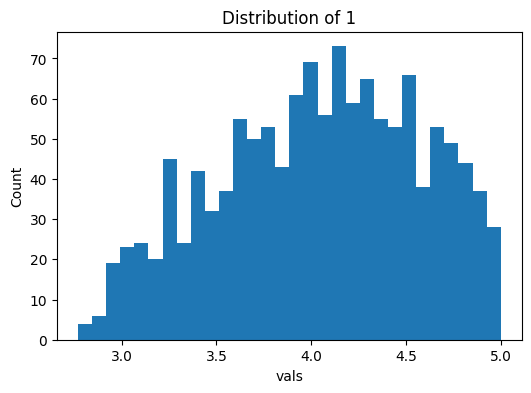

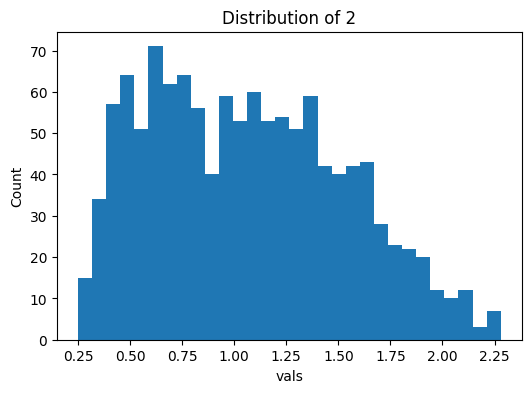

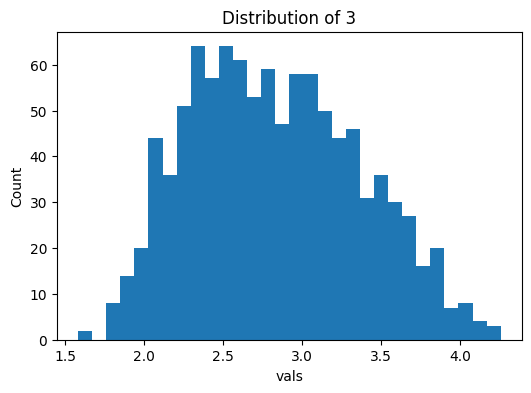

In [121]:
for i in range(0,4):
    cluster_info = rfm_df[rfm_df['cluster'] == i]
    plt.figure(figsize=(6, 4))
    plt.hist(cluster_info[f"RFM_score"], bins=30)
    plt.title(f"Distribution of {i}")
    plt.xlabel("vals")
    plt.ylabel("Count")
    plt.show()

In [122]:
rfm_df

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,3.11,3,-0.507979,1.833806
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,4.56,1,2.484704,-0.385319
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,3.46,3,0.782264,0.959285
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,-0.587438
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,1.10,2,-1.953568,0.674017
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,0.68,2,-2.224030,0.348878
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,0.46,2,-2.240637,-0.163919
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,1.64,0,-0.241653,-1.744960
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,4.33,1,2.390102,-0.349003


In [123]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
reference_date = df["InvoiceDate"].max() + pd.Timedelta(days=1)

customer_df = (
    df.groupby("CustomerID")
      .agg(
          monetary=("Transaction_Total", "sum"),
          frequency=("InvoiceNo", "nunique"),
          total_quantity=("Quantity", "sum"),
          unique_products=("StockCode", "nunique"),
          last_purchase=("InvoiceDate", "max")
      )
      .reset_index()
)

customer_df = customer_df[['CustomerID', 'total_quantity', 'unique_products', 'last_purchase']]
customer_df

,CustomerID,total_quantity,unique_products,last_purchase
0,12346.0,74215,1,2011-01-18 10:01:00
1,12347.0,2458,103,2011-12-07 15:52:00
2,12348.0,2341,22,2011-09-25 13:13:00
3,12349.0,631,73,2011-11-21 09:51:00
4,12350.0,197,17,2011-02-02 16:01:00
...,...,...,...,...
4333,18280.0,45,10,2011-03-07 09:52:00
4334,18281.0,54,7,2011-06-12 10:53:00
4335,18282.0,103,12,2011-12-02 11:43:00
4336,18283.0,1357,263,2011-12-06 12:02:00


In [124]:
import pandas as pd
comparison_data = pd.merge(rfm_df, customer_df, on='CustomerID')
comparison_data

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2,total_quantity,unique_products,last_purchase
0,12346.0,326,1,77183.60,161.0,747.0,4329.0,3.751165,17.219917,99.792531,3.11,3,-0.507979,1.833806,74215,1,2011-01-18 10:01:00
1,12347.0,2,7,4310.00,4202.5,3710.0,4004.0,97.914725,85.523283,92.300599,4.56,1,2.484704,-0.385319,2458,103,2011-12-07 15:52:00
2,12348.0,75,4,1797.24,1653.0,3030.5,3335.0,38.513514,69.859382,76.878746,3.46,3,0.782264,0.959285,2341,22,2011-09-25 13:13:00
3,12349.0,19,1,1757.55,3182.0,747.0,3312.0,74.137931,17.219917,76.348548,2.97,0,0.237304,-0.587438,631,73,2011-11-21 09:51:00
4,12350.0,310,1,334.40,230.5,747.0,1242.0,5.370457,17.219917,28.630705,1.10,2,-1.953568,0.674017,197,17,2011-02-02 16:01:00
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
4333,18280.0,278,1,180.60,353.0,747.0,571.0,8.224604,17.219917,13.162748,0.68,2,-2.224030,0.348878,45,10,2011-03-07 09:52:00
4334,18281.0,181,1,80.82,859.5,747.0,104.0,20.025629,17.219917,2.397418,0.46,2,-2.240637,-0.163919,54,7,2011-06-12 10:53:00
4335,18282.0,8,2,178.05,3794.5,1911.0,551.0,88.408667,44.052559,12.701706,1.64,0,-0.241653,-1.744960,103,12,2011-12-02 11:43:00
4336,18283.0,4,16,2045.53,4015.0,4182.0,3465.0,93.546132,96.403873,79.875519,4.33,1,2.390102,-0.349003,1357,263,2011-12-06 12:02:00


In [125]:
cluster0 = comparison_data[comparison_data['cluster'] == 0]
cluster0.describe()

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2,total_quantity,unique_products,last_purchase
count,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.000000,830.0,830.000000,830.000000,830.000000,830.000000,830
mean,15450.336145,26.721687,1.633735,392.874916,2978.219880,1412.923494,1283.045783,69.390025,32.570850,29.576897,1.819181,0.0,-0.477066,-1.034678,248.434940,31.462651,2011-11-13 06:29:40.843373568
min,12349.000000,1.000000,1.000000,6.900000,1781.000000,747.000000,3.000000,41.495806,17.219917,0.069156,0.660000,0.0,-1.722229,-2.336436,1.000000,1.000000,2011-10-02 12:45:00
25%,13980.000000,14.000000,1.000000,214.465000,2434.000000,747.000000,723.750000,56.710158,17.219917,16.683956,1.330000,0.0,-1.015856,-1.387827,120.000000,12.000000,2011-11-01 10:02:30
50%,15518.000000,24.000000,2.000000,347.415000,2948.500000,1911.000000,1289.500000,68.697577,44.052559,29.725680,1.795000,0.0,-0.556792,-0.991450,200.500000,24.000000,2011-11-15 16:19:00
75%,16935.250000,39.000000,2.000000,516.272500,3462.500000,1911.000000,1804.000000,80.673346,44.052559,41.585984,2.290000,0.0,0.057378,-0.650595,320.000000,41.000000,2011-11-25 14:11:15
max,18282.000000,69.000000,7.000000,3861.000000,4292.000000,3710.000000,3948.000000,100.000000,85.523283,91.009682,3.550000,0.0,0.967999,0.007780,1985.000000,166.000000,2011-12-09 12:16:00
std,1713.449059,16.506266,0.755084,264.417630,638.257605,702.923542,705.837132,14.870867,16.203862,16.271027,0.601954,0.0,0.664647,0.491507,191.243729,27.177040,NaN


In [126]:
cluster1 = comparison_data[comparison_data['cluster'] == 1]
cluster1.describe()

,CustomerID,recency,frequency,monetary,R_rank,F_rank,M_rank,R_rank_norm,F_rank_norm,M_rank_norm,RFM_score,cluster,PC1,PC2,total_quantity,unique_products,last_purchase
count,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.000000,1283.0,1283.000000,1283.000000,1283.000000,1283.000000,1283
mean,15208.318005,16.569758,9.717069,5257.320382,3415.421668,3568.077553,3492.308652,79.576460,82.251672,80.505040,4.042798,1.0,1.847807,-0.065378,3002.063913,123.681995,2011-11-23 11:31:32.782541056
min,12347.000000,1.000000,2.000000,400.860000,1454.000000,1911.000000,1493.000000,33.876980,44.052559,34.416782,2.770000,1.0,0.703725,-1.378865,17.000000,1.000000,2011-09-11 11:30:00
25%,13749.000000,5.000000,4.000000,1397.015000,2948.500000,3030.500000,3075.500000,68.697577,69.859382,70.896727,3.650000,1.0,1.402513,-0.396047,799.000000,54.000000,2011-11-16 12:25:30
50%,15125.000000,12.000000,7.000000,2364.250000,3515.500000,3710.000000,3595.000000,81.908201,85.523283,82.872291,4.070000,1.0,1.833479,-0.120921,1381.000000,93.000000,2011-11-27 13:47:00
75%,16715.000000,24.000000,11.000000,4177.610000,3928.000000,4027.500000,3992.500000,91.519105,92.842324,92.035500,4.460000,1.0,2.293748,0.266862,2486.000000,156.000000,2011-12-05 11:51:00
max,18283.000000,90.000000,209.000000,280206.020000,4292.000000,4338.000000,4338.000000,100.000000,100.000000,100.000000,5.000000,1.0,2.996402,1.629700,196915.000000,1787.000000,2011-12-09 12:50:00
std,1718.714406,14.407284,12.374307,15803.465489,628.312932,537.300671,595.659442,14.639164,12.385908,13.731200,0.531765,0.0,0.573071,0.513740,8717.334124,126.491594,NaN


In [129]:
cluster_summary = comparison_data.groupby('cluster').agg({
    'recency': 'mean',
    'frequency': 'mean',
    'monetary': 'mean',
    'total_quantity': 'mean',
    'unique_products': 'mean',
    'CustomerID': 'count'
}).rename(columns={'CustomerID': 'Customer_Count'})

In [131]:
display(cluster_summary)

,recency,frequency,monetary,total_quantity,unique_products,Customer_Count
cluster,,,,,,
0,26.721687,1.633735,392.874916,248.434940,31.462651,830
1,16.569758,9.717069,5257.320382,3002.063913,123.681995,1283
2,206.879039,1.169014,288.728957,169.880696,19.384424,1207
3,106.367387,3.239686,1441.537144,873.386051,57.560904,1018


In [134]:
print(cluster_summary.to_string())

            recency  frequency     monetary  total_quantity  unique_products  Customer_Count
cluster                                                                                     
0         26.721687   1.633735   392.874916      248.434940        31.462651             830
1         16.569758   9.717069  5257.320382     3002.063913       123.681995            1283
2        206.879039   1.169014   288.728957      169.880696        19.384424            1207
3        106.367387   3.239686  1441.537144      873.386051        57.560904            1018
